# Lab 5-09：什麼時候才值得用多個 agent——CrewAI 實測

**目標**：用 CrewAI 把同一個「查 502 根因」的任務做成三種版本，實際量 token、時間、結果，回答投影片的問題：什麼時候才拆成多個 agent？

| 版本 | 拆法 |
|---|---|
| A 單一 agent | 一個 agent、全部工具 |
| B 依角色硬拆 | 文件 agent、資料庫 agent、運維 agent，最後主管彙整（本課的反模式） |
| C 平行查證＋獨立審查 | 每個懷疑的原因一個唯讀查證員，平行跑；另一個 agent 只負責審查 |

**你會學到**
- CrewAI 的三個概念：`Agent`（角色）、`Task`（工作）、`Crew`（怎麼排）
- `async_execution=True` 讓互相獨立的任務平行跑；`context=[...]` 把結果交給下一個任務
- 多 agent 的成本：token 與時間怎麼長大
- 「依職能切」與「依 context／平行／審查切」的差別

**前置**：Lab 5-C（06）；先讀 `00_concepts.md` 第 7 節。

**對應投影片**：「什麼時候切多個 agent」「多 agent 的 token 代價」「子 agent 傳遞上下文」「智能體動物園」「選型：Agent 與多智能體模式」

![單一 agent 與多 agent 拆法對照圖](images/single_vs_multi.jpg)

*圖：左邊是依角色硬拆：主管把問題轉給文件、資料庫、運維 agent，每轉一次就掉一點細節。右邊是本課認可的拆法：每個懷疑的原因開一個唯讀查證員平行跑，結果匯給一個獨立的審查者。*

## Step 1：接上本機模型

CrewAI 用自己的 `LLM` 類別；`ollama/` 前綴加上 `base_url` 就會連本機 Ollama。
先關掉 CrewAI 預設的遙測與 tracing（不需要，也不想把資料送出去）。`context_window_size` 告訴它這台 Ollama 只有 4096。

In [1]:
import os

os.environ["CREWAI_TRACING_ENABLED"] = "false"
os.environ["CREWAI_DISABLE_TELEMETRY"] = "true"
os.environ["OTEL_SDK_DISABLED"] = "true"

import logging

logging.getLogger("crewai").setLevel(logging.ERROR)

from crewai import LLM, Agent, Crew, Process, Task

def make_llm() -> LLM:
    return LLM(model="ollama/qwen2.5:3b", base_url="http://localhost:11434", temperature=0, context_window_size=4096)


print(make_llm().call("用一句繁體中文說：你好。"))

你好。


## Step 2：工具

CrewAI 的 `@tool` 用 docstring 當說明。三個唯讀工具：讀日誌、查指標、讀 runbook。

In [2]:
from pathlib import Path

from crewai.tools import tool

import oncall_tools as ot


@tool("read_logs")
def read_logs(service: str, level: str = "ERROR") -> str:
    """讀某個服務的日誌。service 是服務名稱（web-gateway、order-api、order-db-proxy、payment-api、notification），level 是 INFO、WARN 或 ERROR。"""
    return ot.read_logs(service if service in ot.SERVICES else None, level, limit=5)


@tool("query_metrics")
def query_metrics(service: str, metric: str = "error_rate") -> str:
    """查某個服務的指標。metric 是 error_rate、p95_latency_ms 或 pool_used（只有 order-db-proxy 有）。"""
    return ot.query_metrics(service, metric)


@tool("read_runbook")
def read_runbook(name: str) -> str:
    """讀一份處理手冊。name 是 502-gateway、db-connection-pool、payment-retry、restart-policy、deploy-freeze 其中之一。"""
    path = Path("data/runbooks") / f"{name.removesuffix('.md')}.md"
    return path.read_text(encoding="utf-8") if path.exists() else "沒有這份手冊"


print(query_metrics.run(service="order-db-proxy", metric="pool_used"))

order-db-proxy pool_used 最近：14:00=46, 14:05=50, 14:10=50, 14:15=50, 14:20=50, 14:25=50；目前 50（上限 50）


## Step 3：量測工具

每個版本都跑同一個問題，記錄：耗時、`token_usage`、模型請求次數，以及答案有沒有指出真正的根因（order-db-proxy 連線池）。

注意：CrewAI 的 token 計數是記在 `LLM` 物件上的，所以**每個版本用一個新的 `LLM`**，數字才不會累加到下一個版本。

In [3]:
import time

QUESTION = "晨光外送的使用者下單一直看到 502。請找出根因是哪個服務、什麼問題，並附上指標數字。"


def is_correct(text: str) -> bool:
    return "order-db-proxy" in text and any(w in text for w in ("連線池", "連接池", "pool"))


async def measure(name: str, crew: Crew) -> dict:
    t0 = time.time()
    result = await crew.kickoff_async()  # notebook 裡已有 event loop，要用 async 版本
    usage = result.token_usage
    row = {"name": name, "seconds": time.time() - t0, "tokens": usage.total_tokens,
           "requests": usage.successful_requests, "agents": len(crew.agents),
           "correct": is_correct(result.raw), "answer": result.raw}
    print(f"[{name}] {row['seconds']:.0f}s，{row['tokens']} tokens，{row['requests']} 次請求，根因正確：{row['correct']}")
    print("答案：", result.raw[:300])
    return row


results = []

## Step 4：版本 A——單一 agent

一個值班 agent，三個工具都給它。`max_iter` 是 CrewAI 的保險絲（等於 `max_steps`）。

In [4]:
llm = make_llm()
oncall = Agent(role="值班工程師", goal="找出 502 的根因並附上證據",
               backstory="你在晨光外送值班，只讀不寫，用繁體中文回答。先看錯誤日誌，再查可疑服務的指標。",
               tools=[read_logs, query_metrics, read_runbook], llm=llm, max_iter=6, verbose=False)
task_a = Task(description=QUESTION + "提示：先用 read_logs 看 order-api 的 ERROR，再查它等待的下游服務的 pool_used。",
              expected_output="三行：根因服務與問題、證據（數字）、建議處理", agent=oncall)
results.append(await measure("A 單一 agent", Crew(agents=[oncall], tasks=[task_a], process=Process.sequential, verbose=False)))

[A 單一 agent] 3s，1356 tokens，2 次請求，根因正確：True
答案： 根因服務為 order-api，問題為等待下游服務 order-db-proxy 的連接池已滿，導致連接超時。證據為 order-api 的錯誤日誌顯示，它在等待 order-db-proxy 的連接池時，已經超過了設定的 5000ms 超時時間。建議處理為增加 order-db-proxy 的連接池大小，或優化 order-api 的請求頻率，以減少對下游服務的壓力。




## Step 5：版本 B——依角色硬拆（反模式）

依「職能」切成三個 agent，各自只拿自己那一類工具，最後主管彙整。這是很多 2024 年教材的標準寫法。
問題在於：「502 是不是資料庫連線池滿了？」這個問題**橫跨**日誌、指標、手冊三種資料，每個 agent 只看得到一角，資訊靠文字轉手。

In [5]:
llm = make_llm()
doc_agent = Agent(role="文件 agent", goal="從手冊找出 502 的處理方式", backstory="你只會讀手冊，用繁體中文回答。",
                  tools=[read_runbook], llm=llm, max_iter=4, verbose=False)
db_agent = Agent(role="資料庫 agent", goal="檢查資料庫相關指標", backstory="你只會查指標，用繁體中文回答。",
                 tools=[query_metrics], llm=llm, max_iter=4, verbose=False)
ops_agent = Agent(role="運維 agent", goal="檢查服務日誌", backstory="你只會讀日誌，用繁體中文回答。",
                  tools=[read_logs], llm=llm, max_iter=4, verbose=False)
manager = Agent(role="主管 agent", goal="彙整各組回報，判斷根因", backstory="你不能自己查資料，只能根據各組回報下結論，用繁體中文回答。",
                llm=llm, verbose=False)

t_doc = Task(description="讀 502-gateway 手冊，摘要處理步驟。", expected_output="三行摘要", agent=doc_agent)
t_db = Task(description="查 order-db-proxy 的 pool_used 指標並回報。", expected_output="兩行：數字與判斷", agent=db_agent)
t_ops = Task(description="讀 order-api 的 ERROR 日誌並回報。", expected_output="兩行：看到什麼錯誤", agent=ops_agent)
t_mgr = Task(description=QUESTION + "根據前面三份回報下結論。", expected_output="三行：根因、證據、建議",
             agent=manager, context=[t_doc, t_db, t_ops])
results.append(await measure("B 依角色硬拆", Crew(agents=[doc_agent, db_agent, ops_agent, manager],
                                          tasks=[t_doc, t_db, t_ops, t_mgr], process=Process.sequential, verbose=False)))

[B 依角色硬拆] 9s，13212 tokens，28 次請求，根因正確：True
答案： 根因：order-db-proxy 的連線池已達上限，無法處理更多的請求。

證據：order-db-proxy 的 pool_used 指標為 50，目前的上限也是 50。錯誤日誌顯示，order-api 在連接 order-db-proxy 時遇到超時錯誤，共計出現了 5 次。

建議：增加 order-db-proxy 的連線池上限，以應對可能的流量激增。同时，檢查是否有其他請求正在等待連線，並優先處理這些請求。此外，考慮增加 order-api 的超時設置，以減少因連接問題導致的錯誤。


## Step 6：版本 C——平行查證＋獨立審查

這是投影片列出的兩種「值得拆」的理由：
- **平行查證**：每個懷疑的原因開一個唯讀查證員，互不依賴，`async_execution=True` 讓它們同時跑；每個只看自己那條線索，context 乾淨。
- **寫的和審的分開**：審查者不查資料，只檢查每份結論有沒有數字證據，再挑出根因。

注意：平行的任務要用**不同的 Agent 物件**（同一個 agent 不能同時跑兩件事）。

In [6]:
llm = make_llm()


def investigator(hypothesis: str) -> Agent:
    return Agent(role=f"查證員：{hypothesis}", goal=f"查證「{hypothesis}」是否成立",
                 backstory="你只讀不寫，用繁體中文回答，結論一定要附數字。",
                 tools=[read_logs, query_metrics], llm=llm, max_iter=4, verbose=False)


HYPOTHESES = {
    "order-db-proxy 連線池用盡": "用 query_metrics 查 order-db-proxy 的 pool_used（上限 50）。",
    "payment-api 異常": "用 query_metrics 查 payment-api 的 error_rate（超過 2% 才算異常）。",
    "web-gateway 本身故障": "用 read_logs 看 web-gateway 的 ERROR，判斷是 gateway 自己壞還是上游沒回應。",
}
inv_tasks = [Task(description=f"查證：{h}。{how}", expected_output="三行：結論（成立／不成立）、證據（數字）、信心",
                  agent=investigator(h), async_execution=True) for h, how in HYPOTHESES.items()]
reviewer = Agent(role="審查者", goal="檢查每份查證是否有數字證據，挑出真正的根因",
                 backstory="你不信任沒有數字的結論，也不自己查資料。用繁體中文回答。", llm=llm, verbose=False)
t_review = Task(description=QUESTION + "根據三份查證，挑出證據最充分的根因；沒有數字支持的結論要排除。",
                expected_output="三行：根因、採信的證據、被排除的假設", agent=reviewer, context=inv_tasks)
crew_c = Crew(agents=[t.agent for t in inv_tasks] + [reviewer], tasks=[*inv_tasks, t_review],
              process=Process.sequential, verbose=False)
results.append(await measure("C 平行查證＋審查", crew_c))

[C 平行查證＋審查] 10s，14116 tokens，28 次請求，根因正確：True
答案： 根因：order-api
採信的證據：order-db-proxy 的 pool_used 最近一直維持在 50，達到上限
被排除的假設：payment-api 的 error_rate 最近均為 0.6，未超過 2% 的門檻；web-gateway 在過去 5 分鐘內收到了 5 次 502 Bad Gateway 的錯誤，這些錯誤都是因為 upstream order-api 沒有回應


點一下：看三份查證各自說了什麼。3B 查證員可能把 0.6% 讀成 60%、輸出格式不一，或在證據不足時下結論——這正是要有審查者的原因。
也要檢查審查者本身：它可能採信了正確的證據，卻在「根因」那一行寫錯服務名稱。審查者也是 3B，一樣會錯。

In [7]:
for t in inv_tasks:
    print(f"--- {t.agent.role}\n{t.output.raw[:250]}\n")

--- 查證員：order-db-proxy 連線池用盡
{
  "結論": "成立",
  "證據": "order-db-proxy 的 pool_used 最近一直維持在 50，達到上限",
  "信心": 100
}

--- 查證員：payment-api 異常
{
  "結論": "不成立",
  "證據": "payment-api 的 error_rate 最近均為 0.6，未超過 2% 的門檻",
  "信心": 100
}

--- 查證員：web-gateway 本身故障
結論：不成立
證據：web-gateway 在過去 5 分鐘內收到了 5 次 502 Bad Gateway 的錯誤，這些錯誤都是因為 upstream order-api 沒有回應，而不是 web-gateway 自己壞了。
信心：95%

根據上述日誌，web-gateway 當前並未顯示任何自己故障的錯誤訊息，而是因為 upstream service (order-api) 沒有回應而顯示 502 Bad Gateway 的錯誤。因此，可以判斷 web-gateway 本身並未出現故障。



## Step 7：畫出代價

三張圖：token、時間、agent 數量；標題標出答案是否找對根因。

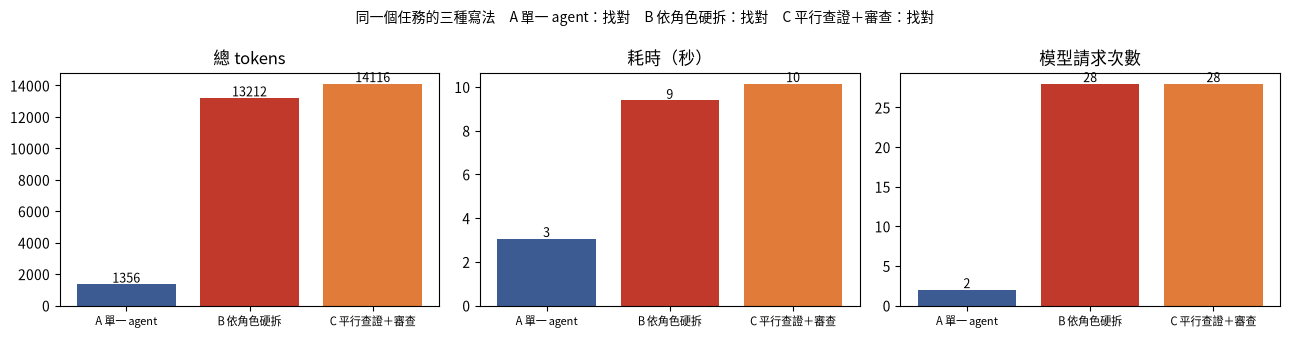

A 單一 agent   tokens 是單一 agent 的 1.0 倍，1 個 agent
B 依角色硬拆      tokens 是單一 agent 的 9.7 倍，4 個 agent
C 平行查證＋審查    tokens 是單一 agent 的 10.4 倍，4 個 agent


In [8]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

names = [r["name"] for r in results]
colors = ["#3b5b92", "#c0392b", "#e07b39"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, key, label in zip(axes, ["tokens", "seconds", "requests"], ["總 tokens", "耗時（秒）", "模型請求次數"]):
    ax.bar(names, [r[key] for r in results], color=colors)
    for i, r in enumerate(results):
        ax.text(i, r[key], f"{r[key]:.0f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(label)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("同一個任務的三種寫法　" + "　".join(f"{r['name']}：{'找對' if r['correct'] else '沒找對'}" for r in results), fontsize=10)
plt.tight_layout()
plt.show()

base = results[0]["tokens"]
for r in results:
    print(f"{r['name']:<12} tokens 是單一 agent 的 {r['tokens'] / base:.1f} 倍，{r['agents']} 個 agent")

## Step 8：怎麼讀這個結果

數字每次跑都會有些不同，但趨勢很穩定：
- **多 agent 一定比較貴**：每多一個 agent，就多一份 system prompt、多幾輪請求。投影片引用的數字是 3～15 倍。
- **B 依角色硬拆**：最貴的地方不是 token，而是**轉手**。主管看不到原始資料，只能相信三份摘要；任何一份抄錯數字，結論就跟著錯。
- **C 平行查證＋審查**：一樣比 A 貴，但換到兩個好處——三條線索同時查（真實系統裡每條要查很久時才有意義），以及有人專門挑證據的毛病。
- **A 單一 agent**：問題小、工具少的時候，通常就夠了。

回到投影片「什麼時候切多個 agent」：**先用一個 agent；有證據顯示 context 不夠、需要平行、需要獨立審查、或有權限邊界時才拆，而且按這些理由拆，不按職能拆。**

## 試試看

1. 在版本 C 加第四個假設「order-api 程式錯誤」，看 token 增加多少、審查者會不會被干擾。
2. 把版本 B 的主管 agent 加上 `tools=[query_metrics]`，讓它可以自己查——這時它還需要三個下屬嗎？
3. 把版本 C 的 `async_execution=True` 拿掉，比較耗時。3B 模型在同一張 GPU 上，平行不一定比較快——為什麼？

## 小結

- CrewAI 用 Agent／Task／Crew 描述多 agent；`async_execution` 平行、`context` 傳遞結果。
- 多 agent 的成本是 token、時間與轉手的資訊損失；值得拆的理由是隔離 context、平行查證、獨立審查、權限邊界。
- 下一本 10 把模組 5 的所有寫法放在一起比：行數、控制權、適用情境。